# Notebook 4 - Modèle MICRO : quels assurés sont les plus exposés à un accident ?

**Question :** à partir du profil d'un assuré (âge, sexe, salaire, profession, entreprise…), peut-on estimer son risque d'accident du travail ?

**Cible :** `STATUT_AT` (`AVEC_AT` = 1, `SANS_AT` = 0).

**Objectif du cahier des charges :** détecter **au moins 75 %** des assurés qui auront un accident (rappel ≥ 0,75).

⚠️ La variable `NOMBRE_ATM` n'est **pas** utilisée : le notebook 1 a montré qu'elle contient directement la réponse (`NOMBRE_ATM ≥ 1` ⇔ `AVEC_AT`). Même chose pour `ANNEE_ACCIDENT` et `CLASSE_ANCIENNETE_AVANT_AT`, qui ne sont remplies que pour les accidentés.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, recall_score, precision_score, confusion_matrix, classification_report

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

trv = pd.read_parquet("data/travailleurs_propre.parquet")
ent = pd.read_parquet("data/entreprises_propre.parquet")

## 1. Préparer les variables

In [2]:
# Cible
trv["accident"] = (trv["STATUT_AT"] == "AVEC_AT").astype(int)

# Profession : on garde les 30 plus fréquentes, les autres deviennent "AUTRE"
top_professions = trv["PROFESSION"].value_counts().head(30).index
trv["profession"] = trv["PROFESSION"].where(trv["PROFESSION"].isin(top_professions), "AUTRE")
trv.loc[trv["PROFESSION"].isna(), "profession"] = "NON RENSEIGNE"

# Nationalité : les 10 plus fréquentes, les autres deviennent "AUTRE"
top_nationalites = trv["NATIONALITE"].value_counts().head(10).index
trv["nationalite"] = trv["NATIONALITE"].where(trv["NATIONALITE"].isin(top_nationalites), "AUTRE")

# Caractéristiques de l'employeur (dernière année connue)
ent_derniere = ent.sort_values("ANNEE").drop_duplicates("ENTREPRISE_ID", keep="last")
trv = trv.merge(ent_derniere[["ENTREPRISE_ID", "CLASSE_EFFECTIF", "CLASSE_MASSE_SALARIALE"]], on="ENTREPRISE_ID", how="left")

variables = ["SEXE", "CLASSE_AGE", "CLASSE_SALAIRE", "CLASSE_ANCIENNETE_ENTREPRISE",
             "profession", "nationalite", "CLASSE_EFFECTIF", "CLASSE_MASSE_SALARIALE"]

# Valeurs manquantes -> modalité "NON RENSEIGNE"
for col in variables:
    trv[col] = trv[col].astype("string").fillna("NON RENSEIGNE")

X = pd.get_dummies(trv[variables], dtype=np.uint8)
y = trv["accident"]
print("Nombre d'assurés :", X.shape[0], " - nombre de colonnes après encodage :", X.shape[1])

Nombre d'assurés : 1041741  - nombre de colonnes après encodage : 78


## 2. Découper en trois jeux

* **entraînement (60 %)** : pour apprendre ;
* **validation (20 %)** : pour choisir le seuil de décision ;
* **test (20 %)** : pour l'évaluation finale, sur des données jamais vues.

`stratify=y` garde la même proportion d'accidentés (~4 %) dans chaque jeu.

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
print("train :", len(X_train), " val :", len(X_val), " test :", len(X_test))

train : 625044  val : 208348  test : 208349


## 3. Choix du modèle : pourquoi la forêt aléatoire (comparée à la régression logistique) ?

La forêt aléatoire était **prévue par le cahier des charges** du projet. Plutôt que de l'appliquer sans discuter, on vérifie qu'elle est **appropriée aux données**, et on la compare à une référence simple.

Caractéristiques des données et conséquences :
* **variables surtout catégorielles / ordinales** (classes d'âge, de salaire, d'effectif, profession, nationalité) : pas besoin de mise à l'échelle ; la forêt les gère directement ;
* **effets de seuil et non-linéarités** (ex. le risque s'effondre après 66 ans, bondit pour les nouveaux arrivants) : une forêt les capte sans qu'on les spécifie à la main ;
* **interactions** (profession × type d'entreprise) : captées par les arbres ;
* **cible rare (4,3 %)** : traitée par `class_weight="balanced"` ;
* **robustesse** : le bagging limite le sur-apprentissage et rend le modèle peu sensible aux valeurs extrêmes.

| Candidat | Rôle | Raison |
|---|---|---|
| **Régression logistique** | référence | simple et explicable ; mais linéaire : elle suppose des effets additifs, et ne capte les seuils/interactions que si on les ajoute à la main |
| **Forêt aléatoire** | **retenue (cahier des charges)** | capte seuils, non-linéarités et interactions automatiquement ; importance des variables ; robuste au bruit |
| **Gradient boosting** | piste d'amélioration | souvent un cran au-dessus, mais plus de réglages et de risque de sur-apprentissage ; gardé comme perspective |

On entraîne les **deux** modèles : si la forêt n'apporte rien de plus que la régression logistique, c'est en soi une information (les relations sont alors quasi linéaires). `class_weight="balanced"` compense la rareté des accidentés.

In [4]:
logit = LogisticRegression(class_weight="balanced", max_iter=1000)
logit.fit(X_train, y_train)

foret = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50, max_samples=0.3,
                               class_weight="balanced", n_jobs=-1, random_state=42)
foret.fit(X_train, y_train)

proba_logit = logit.predict_proba(X_test)[:, 1]
proba_foret = foret.predict_proba(X_test)[:, 1]

print("AUC-ROC régression logistique :", round(roc_auc_score(y_test, proba_logit), 3))
print("AUC-ROC forêt aléatoire       :", round(roc_auc_score(y_test, proba_foret), 3))

AUC-ROC régression logistique : 0.847
AUC-ROC forêt aléatoire       : 0.847


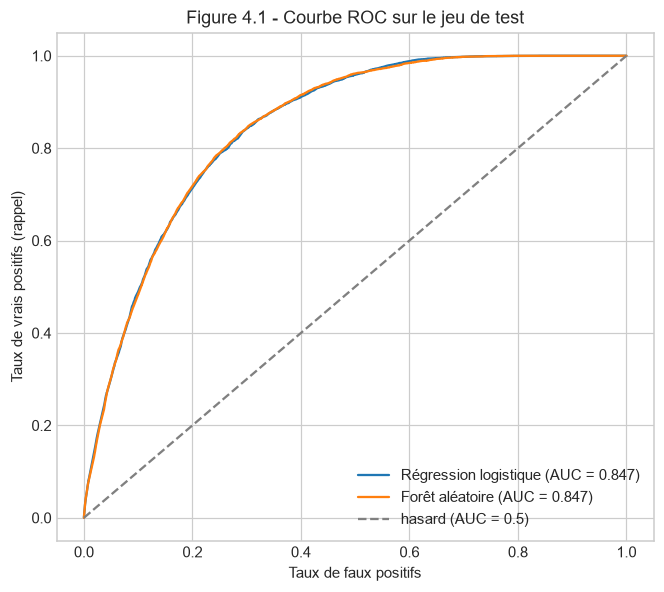

In [5]:
plt.figure(figsize=(7, 6))
for proba, nom in [(proba_logit, "Régression logistique"), (proba_foret, "Forêt aléatoire")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="hasard (AUC = 0.5)")
plt.title("Figure 4.1 - Courbe ROC sur le jeu de test")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.legend()
plt.show()

**Commentaire - Figure 4.1 :** les deux modèles obtiennent une **AUC de 0,847** : si l'on prend au hasard un accidenté et un non-accidenté, le modèle attribue le score le plus élevé à l'accidenté dans 85 % des cas. C'est un **bon résultat** pour un risque individuel prédit à partir de quelques variables administratives.

**Interprétation du match nul forêt / logistique :** l'égalité des AUC indique que, sur ces variables, les relations sont **presque additives** - il n'y a pas d'interactions fortes à exploiter. La forêt aléatoire **reste le choix retenu** (cahier des charges, et elle capte sans risque les effets de seuil comme « 66+ » ou « nouvel arrivant ») ; la régression logistique est une **alternative tout aussi valable et plus explicable**. On poursuit avec la forêt, en gardant en tête que le gradient boosting pourrait apporter un gain marginal.

Seuil retenu : 0.56


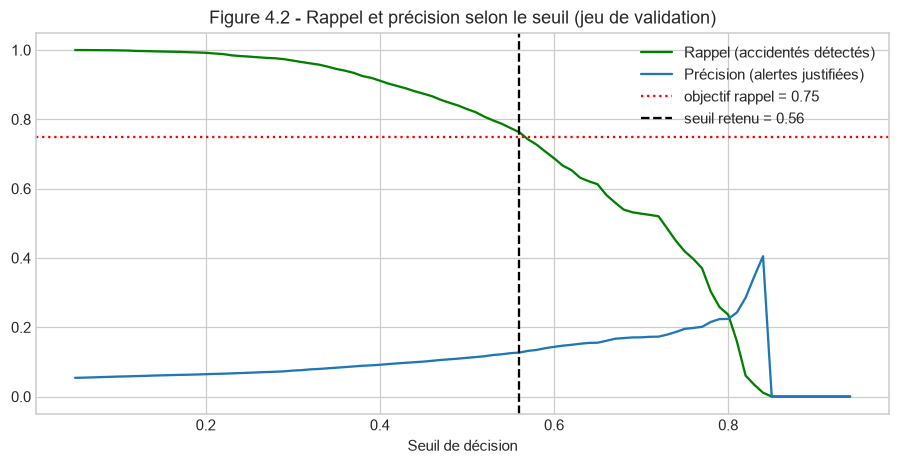

In [6]:
proba_val = foret.predict_proba(X_val)[:, 1]
seuils = np.arange(0.05, 0.95, 0.01)
rappels = [recall_score(y_val, proba_val >= s) for s in seuils]
precisions = [precision_score(y_val, proba_val >= s, zero_division=0) for s in seuils]

seuil = max(s for s, r in zip(seuils, rappels) if r >= 0.75)
print("Seuil retenu :", round(seuil, 2))

plt.figure(figsize=(10, 4.5))
plt.plot(seuils, rappels, label="Rappel (accidentés détectés)", color="green")
plt.plot(seuils, precisions, label="Précision (alertes justifiées)", color="tab:blue")
plt.axhline(0.75, color="red", linestyle=":", label="objectif rappel = 0.75")
plt.axvline(seuil, color="black", linestyle="--", label=f"seuil retenu = {seuil:.2f}")
plt.title("Figure 4.2 - Rappel et précision selon le seuil (jeu de validation)")
plt.xlabel("Seuil de décision")
plt.legend()
plt.show()

**Commentaire - Figure 4.2 :** quand on **baisse le seuil**, on détecte **plus d'accidentés** (rappel ↑), mais on déclenche aussi **plus de fausses alertes** (précision ↓). Le seuil **0,56** est le plus élevé qui respecte l'objectif de 75 % de rappel. Ce choix est fait sur le jeu de **validation**, pour ne pas « tricher » sur le jeu de test.

## 5. Évaluation finale sur le jeu de test

               precision    recall  f1-score   support

Sans accident       0.99      0.76      0.86    199438
Avec accident       0.13      0.77      0.22      8911

     accuracy                           0.76    208349
    macro avg       0.56      0.77      0.54    208349
 weighted avg       0.95      0.76      0.83    208349



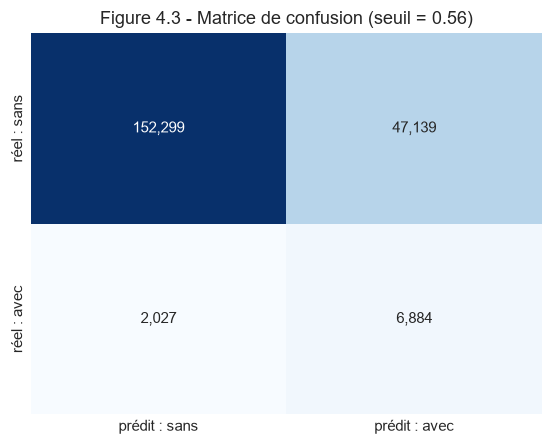

In [7]:
prediction = (proba_foret >= seuil).astype(int)
print(classification_report(y_test, prediction, target_names=["Sans accident", "Avec accident"]))

matrice = confusion_matrix(y_test, prediction)
plt.figure(figsize=(6, 4.5))
sns.heatmap(matrice, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["prédit : sans", "prédit : avec"], yticklabels=["réel : sans", "réel : avec"])
plt.title(f"Figure 4.3 - Matrice de confusion (seuil = {seuil:.2f})")
plt.show()

**Commentaire - Figure 4.3 :**
* Le modèle **détecte 77 % des accidentés** (6 884 sur 8 911) : **l'objectif de 75 % est atteint** sur des données jamais vues.
* En contrepartie, il y a **47 139 fausses alertes**. Sur 100 assurés signalés, environ **13** auront réellement un accident (précision = 0,13).
* C'est **3 fois mieux que le hasard** (4,3 %) : le ciblage est donc réellement utile. Il faut voir ces alertes comme une **liste de visites de prévention à prioriser**, pas comme une certitude.
* Au total, environ **26 % des assurés** sont signalés : la médecine du travail peut concentrer ses efforts sur un quart de la population.

## 6. Variables les plus importantes

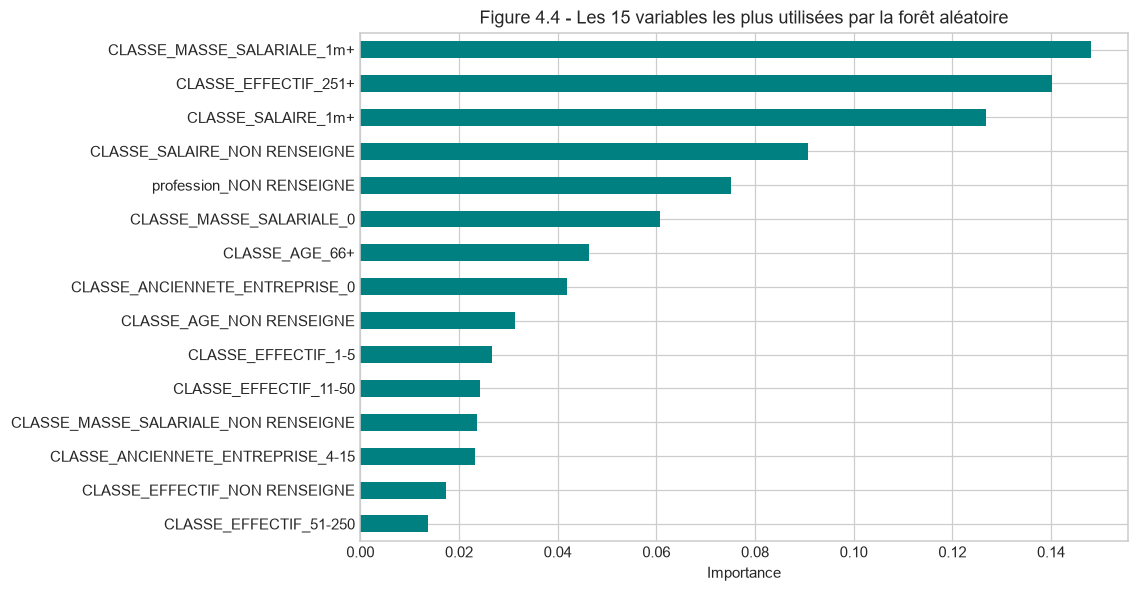

In [8]:
importance = pd.Series(foret.feature_importances_, index=X.columns).sort_values().tail(15)
importance.plot(kind="barh", figsize=(9, 6), color="teal")
plt.title("Figure 4.4 - Les 15 variables les plus utilisées par la forêt aléatoire")
plt.xlabel("Importance")
plt.show()

**Commentaire - Figure 4.4 :**
* Les variables les plus utiles concernent **l'entreprise** (masse salariale « 1m+ », effectif « 251+ ») : travailler dans une grande entreprise augmente fortement le risque **enregistré** d'accident. C'est sans doute aussi parce que les grandes entreprises **déclarent mieux** leurs accidents.
* Puis viennent le **salaire** de l'assuré (« 1m+ »), l'**âge** (66+ = risque très faible) et l'**ancienneté** (0 = nouvel arrivant).
* Les modalités **« NON RENSEIGNE »** (salaire, profession, âge) sont aussi très utilisées : c'est le **biais de saisie** repéré dans le notebook 1. On mesure son effet juste en dessous.

## 7. Vérification : le modèle profite-t-il d'un biais de saisie ?

Le notebook 1 a montré que les assurés dont l'âge ou le salaire est « non renseigné » ont très peu d'accidents. Le dossier d'un accidenté est complété lors du traitement de l'accident ; le modèle peut donc s'appuyer sur ce biais de saisie. On mesure l'AUC **uniquement sur les assurés dont l'âge et le salaire sont renseignés**.

In [9]:
complets = (X_test["CLASSE_AGE_NON RENSEIGNE"] == 0) & (X_test["CLASSE_SALAIRE_NON RENSEIGNE"] == 0)
print("AUC sur tout le jeu de test         :", round(roc_auc_score(y_test, proba_foret), 3))
print("AUC sur les assurés au profil complet :", round(roc_auc_score(y_test[complets], proba_foret[complets]), 3),
      f"({complets.mean():.0%} du jeu de test)")

AUC sur tout le jeu de test         : 0.847
AUC sur les assurés au profil complet : 0.791 (47% du jeu de test)


**Commentaire :** sur les assurés au **profil complet** (âge et salaire renseignés), l'AUC baisse de 0,847 à **0,791**. Une partie de la performance vient donc du **biais de saisie**. Mais le modèle reste **nettement meilleur que le hasard (0,5)** : il a appris de **vrais facteurs de risque** (âge, salaire, profession, type d'entreprise).

➡️ Pour la soutenance, la performance honnête du modèle se situe **entre 0,79 et 0,85 d'AUC**. Pour améliorer la qualité, la CNPS devrait remplir ces informations pour **tous** les assurés, et pas seulement pour les accidentés.

## 8. Utilisation : recommandations de prévention

Pour chaque assuré, le score de risque est traduit en **actions concrètes** pour la médecine du travail.

In [10]:
def recommandations(assure, proba):
    actions = []
    if proba >= seuil:
        actions.append("Visite médicale d'aptitude au poste à programmer")
    if assure["CLASSE_AGE"] in ["<18", "18-25"]:
        actions.append("Formation sécurité obligatoire (jeune travailleur)")
    if assure["CLASSE_ANCIENNETE_ENTREPRISE"] in ["0", "1-3"]:
        actions.append("Accompagnement des nouveaux arrivants (tutorat, accueil sécurité)")
    if assure["CLASSE_EFFECTIF"] in ["51-250", "251+"] and proba >= seuil:
        actions.append("Signaler au service HSE de l'entreprise")
    if not actions:
        actions.append("Suivi standard (calendrier réglementaire)")
    return actions

# 3 assurés du jeu de test : le plus risqué, un assuré moyen, le moins risqué
exemples = trv.loc[X_test.index].assign(score=proba_foret).sort_values("score")
for i in [-1, len(exemples) // 2, 0]:
    assure = exemples.iloc[i]
    print(f"Assuré {assure['TRAVAILLEUR_ID'][:12]}…  âge {assure['CLASSE_AGE']}, sexe {assure['SEXE']}, "
          f"profession {assure['profession']}  ->  score = {assure['score']:.2f}")
    for action in recommandations(assure, assure["score"]):
        print("    •", action)
    print()

Assuré TRV_F2EDF56A…  âge 36-45, sexe M, profession MACHINISTE  ->  score = 0.85
    • Visite médicale d'aptitude au poste à programmer
    • Signaler au service HSE de l'entreprise

Assuré TRV_A6A0A160…  âge NON RENSEIGNE, sexe M, profession MANOEUVRE  ->  score = 0.34
    • Accompagnement des nouveaux arrivants (tutorat, accueil sécurité)

Assuré TRV_3690D629…  âge NON RENSEIGNE, sexe F, profession NON RENSEIGNE  ->  score = 0.00
    • Accompagnement des nouveaux arrivants (tutorat, accueil sécurité)



In [11]:
joblib.dump({"modele": foret, "seuil": seuil, "colonnes": list(X.columns)}, "modeles/micro_foret_aleatoire_assures.joblib")
print("Modèle sauvegardé dans modeles/micro_foret_aleatoire_assures.joblib")

Modèle sauvegardé dans modeles/micro_foret_aleatoire_assures.joblib


**Conclusion du modèle micro :** sans utiliser de variable qui « triche », le modèle détecte **77 % des futurs accidentés** en ne ciblant qu'un quart des assurés.

**Limites :**
1. une partie du signal vient du **biais de saisie** (champs mieux remplis après un accident) : la performance « honnête » se situe entre 0,79 et 0,85 d'AUC ;
2. la précision reste **faible (13 %)** : c'est un outil de **priorisation**, pas de diagnostic individuel ;
3. les données décrivent les accidents **déjà survenus**, sans date d'observation des profils : le modèle repère des profils **semblables** à ceux des accidentés, ce n'est pas une prévision datée.